<a href="https://colab.research.google.com/github/eliezana05/-DI-Bootcamp-Stage1/blob/main/Week3/Day3/Mobile/Data_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Data loading and exploration

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


,Type
battery_power,int64
blue,int64
clock_speed,float64
dual_sim,int64
fc,int64
four_g,int64
int_memory,int64
m_dep,float64
mobile_wt,int64
n_cores,int64


,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


Shape: (2000, 21) Duplicates: 0


,Missing
battery_power,0
blue,0
clock_speed,0
dual_sim,0
fc,0
four_g,0
int_memory,0
m_dep,0
mobile_wt,0
n_cores,0


... (7 outputs left out)

For binary indicators, the mean is the proportion with the feature. Excess kurtosis is measured relative to normal=0; binary shape statistics should not be interpreted as Gaussian diagnostics.


,Spearman rho,p,Bonferroni p,Absolute rho
Feature,,,,
ram,0.917080,0.000000e+00,0.000000e+00,0.917080
battery_power,0.199991,1.722306e-19,3.444611e-18,0.199991
px_width,0.165134,1.074056e-13,2.148113e-12,0.165134
px_height,0.132851,2.461260e-09,4.922521e-08,0.132851
int_memory,0.044278,4.771653e-02,9.543306e-01,0.044278
pc,0.032824,1.422683e-01,1.000000e+00,0.032824
touch_screen,-0.030411,1.739918e-01,1.000000e+00,0.030411
mobile_wt,-0.030214,1.767996e-01,1.000000e+00,0.030214
fc,0.024167,2.800284e-01,1.000000e+00,0.024167


RAM across 4 price groups — Kruskal-Wallis: KruskalResult(statistic=np.float64(1681.4964744599295), pvalue=np.float64(0.0))
Reject equal RAM distributions at 5%.
RAM ANOVA: F_onewayResult(statistic=np.float64(3520.1108238957563), pvalue=np.float64(0.0)) Eta squared: 0.8410363850670016
ANOVA assumes independent errors and comparable within-group variances. Kruskal results supplement it; neither establishes causation.


# 4. Visualizations

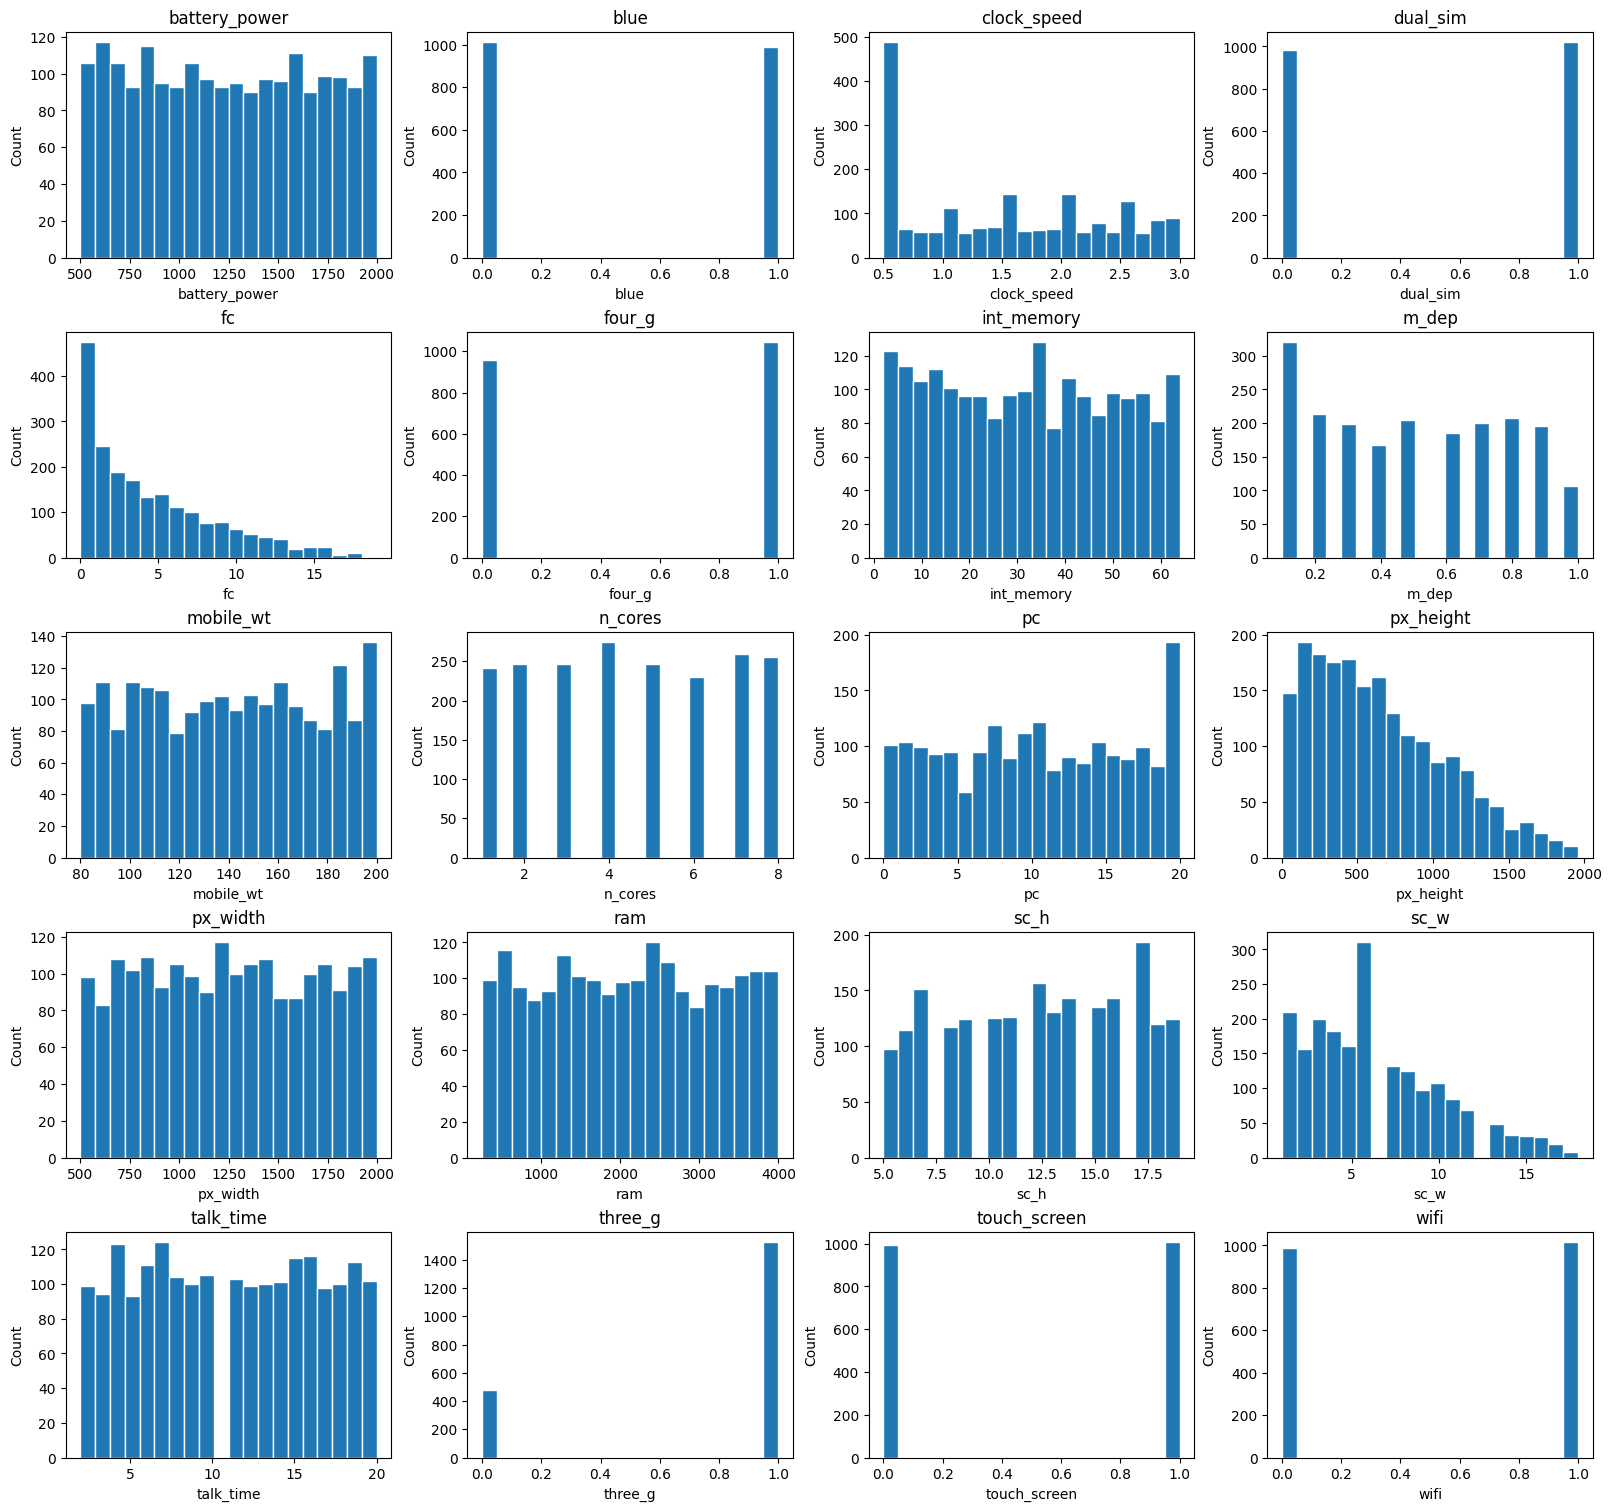

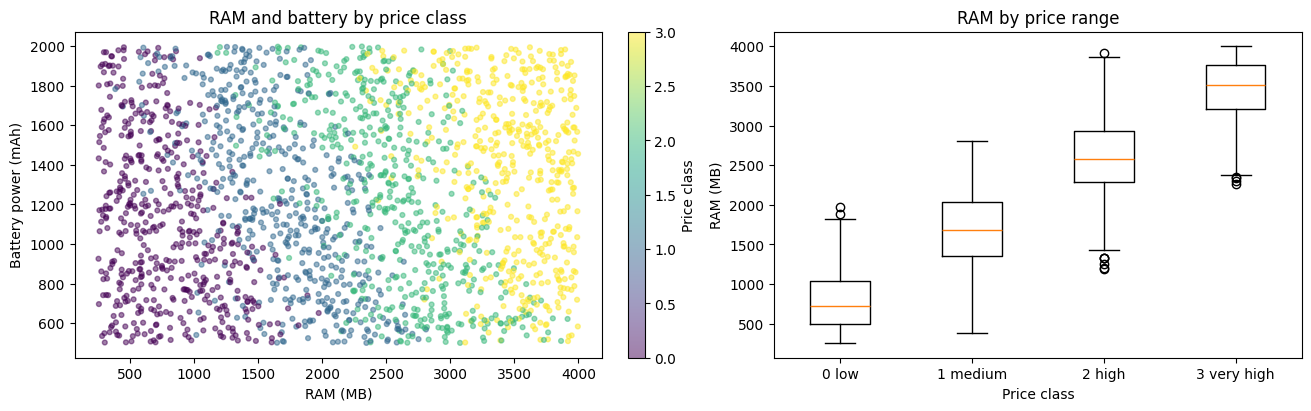

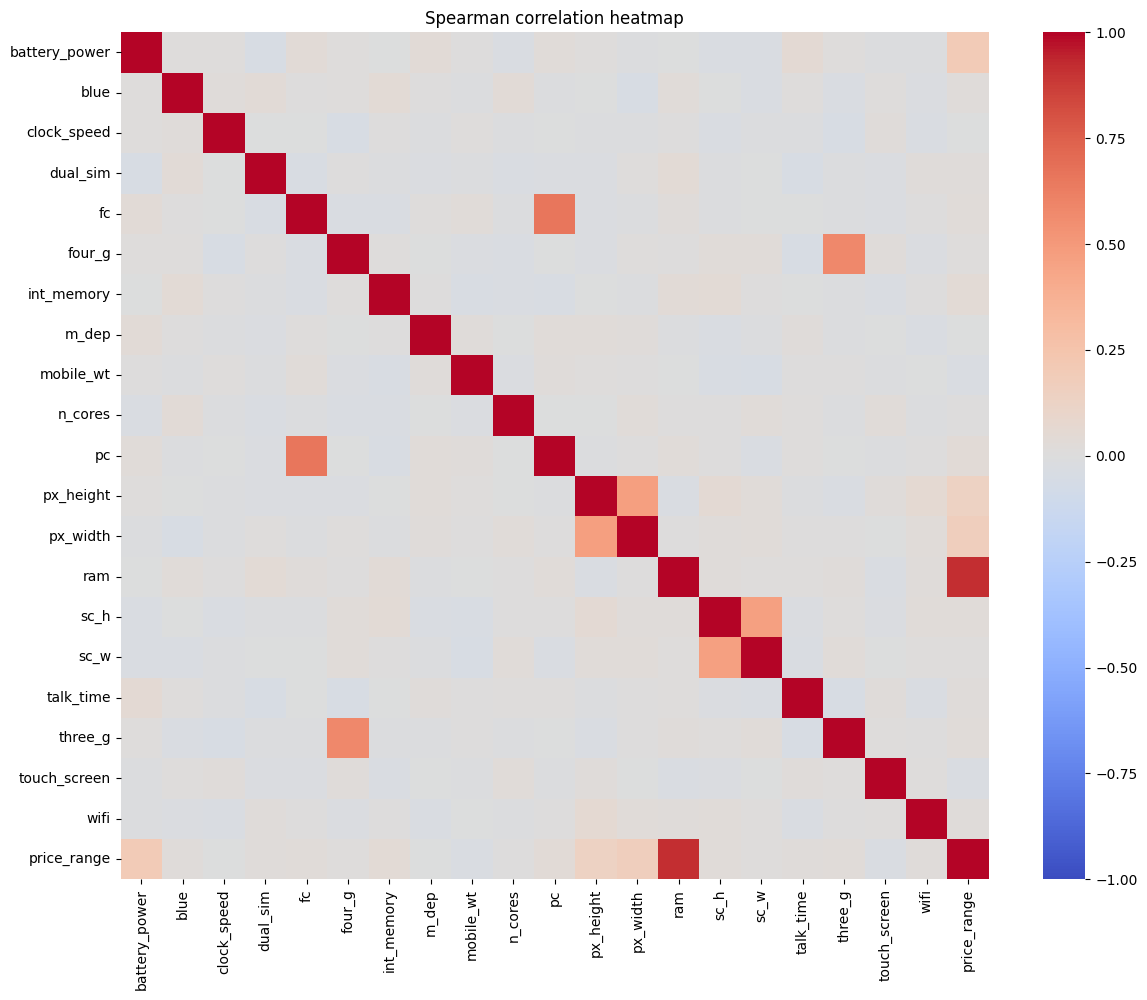

# 5. Insights and conclusion
- Analyzed **2,000** labeled devices and **20** predictors after duplicate handling and documented median imputation of invalid dimensions.
- Strongest monotonic association with price class: **ram**, Spearman rho **0.917**. The ranked table reports all predictors, with Bonferroni adjustment across 20 tests.
- RAM distributions differ across price classes (Kruskal p **0**). RAM ANOVA eta squared is **0.841**, describing between-class separation within this dataset.
- Histograms distinguish binary flags from continuous specifications; the box plot shows group separation and overlap. Correlation alone cannot identify causal determinants or guarantee classification performance.
- Zero camera values were retained because they can describe absence of a camera. Physically impossible display dimensions were treated as missing and imputed; this choice can alter associations and is disclosed.
- Price labels are four ordered categories: these results cannot estimate a price in dollars. A predictive follow-up would require stratified train/test separation and preprocessing fitted on training data only.


Mobile price analysis validation checks passed.


In [1]:
# Comprehensive Mobile Price Analysis — Octopus chapter 3420
import io,zipfile,requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display,Markdown

display(Markdown('# 1. Data loading and exploration'))
url='https://github.com/devtlv/Datasets-DA-Bootcamp-2-/raw/refs/heads/main/Week%206%20-%20Applications%20for%20Data%20Analysis/W6D5%20-%20Mini%20project/Mobile%20Price%20Classification.zip'
r=requests.get(url,timeout=90); r.raise_for_status(); archive=zipfile.ZipFile(io.BytesIO(r.content))
train_files=[n for n in archive.namelist() if n.split('/')[-1].lower()=='train.csv' and '__MACOSX' not in n]
assert len(train_files)==1,archive.namelist()
raw=pd.read_csv(archive.open(train_files[0])); display(raw.head(),raw.dtypes.to_frame('Type'),raw.describe().T)
print('Shape:',raw.shape,'Duplicates:',raw.duplicated().sum()); display(raw.isna().sum().to_frame('Missing'))
print('Target price_range is an ordinal class (0 low, 1 medium, 2 high, 3 very high), not an actual currency amount.')

display(Markdown('# 2. Data cleaning and preprocessing'))
df=raw.drop_duplicates().copy(); df=df.dropna(subset=['price_range'])
assert set(df.price_range).issubset({0,1,2,3})
# Zero front-camera resolution may mean no front camera; preserve it.
# Zero screen width or pixel dimensions are physically invalid, mark missing.
for c in ['sc_w','sc_h','px_height','px_width']:
    if c in df:
        df.loc[df[c]<=0,c]=np.nan
numeric=df.select_dtypes(include=np.number).columns.drop('price_range')
missing_counts=df.isna().sum()
for c in numeric:
    df[c]=df[c].fillna(df[c].median())
# Existing binary columns (e.g., blue, wifi, four_g) are already numeric 0/1.
# If nominal columns occur, one-hot encode rather than invent ordinal labels.
nominal=df.select_dtypes(exclude=np.number).columns.tolist()
if nominal:
    df=pd.get_dummies(df,columns=nominal,dummy_na=True,dtype=int)
display(missing_counts[missing_counts>0].to_frame('Values imputed'))
features=df.columns.drop('price_range'); print('Predictor count:',len(features)); display(df.price_range.value_counts().sort_index().to_frame('Class count'))

# Analysis is descriptive. For prediction, imputation must be fitted only on a
# training split to avoid leakage. No predictive accuracy is claimed here.
display(Markdown('# 3. Statistical analysis of each feature'))
records=[]
for c in features:
    v=df[c].to_numpy(dtype=float)
    records.append([c,np.mean(v),np.median(v),stats.mode(v,keepdims=False).mode,np.ptp(v),np.var(v,ddof=1),np.std(v,ddof=1),stats.skew(v,bias=False),stats.kurtosis(v,fisher=True,bias=False)])
descriptive=pd.DataFrame(records,columns=['Feature','Mean','Median','Mode','Range','Variance','Std','Skewness','Excess kurtosis']).set_index('Feature')
display(descriptive.round(4))
print('For binary indicators, the mean is the proportion with the feature. Excess kurtosis is measured relative to normal=0; binary shape statistics should not be interpreted as Gaussian diagnostics.')

# Feature-target association: target is ordinal, so use Spearman rank correlation.
associations=[]
for c in features:
    result=stats.spearmanr(df[c],df.price_range)
    associations.append([c,result.statistic,result.pvalue])
association=pd.DataFrame(associations,columns=['Feature','Spearman rho','p']).set_index('Feature')
association['Bonferroni p']=np.minimum(association['p']*len(features),1.)
association['Absolute rho']=association['Spearman rho'].abs()
association=association.sort_values('Absolute rho',ascending=False)
display(association)
# H0: distributions of RAM are the same across price groups. Non-parametric
# Kruskal-Wallis is suitable for several independent, non-normal groups.
ram_groups=[group.ram.to_numpy() for _,group in df.groupby('price_range')]
kw=stats.kruskal(*ram_groups)
print('RAM across 4 price groups — Kruskal-Wallis:',kw)
print('Reject equal RAM distributions at 5%.' if kw.pvalue<.05 else 'Do not reject equal RAM distributions at 5%.')
# Additional SciPy analysis: RAM ANOVA and effect-size eta squared.
f_test=stats.f_oneway(*ram_groups)
grand=df.ram.mean(); ss_between=sum(len(v)*(v.mean()-grand)**2 for v in ram_groups); ss_total=np.sum((df.ram.to_numpy()-grand)**2)
eta_squared=ss_between/ss_total
print('RAM ANOVA:',f_test,'Eta squared:',eta_squared)
print('ANOVA assumes independent errors and comparable within-group variances. Kruskal results supplement it; neither establishes causation.')

# Each feature receives a histogram; labels preserve feature names.
display(Markdown('# 4. Visualizations'))
n=len(features); fig,axes=plt.subplots(int(np.ceil(n/4)),4,figsize=(16,3*int(np.ceil(n/4))),constrained_layout=True)
for ax,c in zip(axes.flat,features):
    ax.hist(df[c],bins=20,edgecolor='white'); ax.set(title=c,xlabel=c,ylabel='Count')
for ax in axes.flat[n:]: ax.set_visible(False)
plt.show()
fig,axes=plt.subplots(1,2,figsize=(13,4),constrained_layout=True)
scatter=axes[0].scatter(df.ram,df.battery_power,c=df.price_range,cmap='viridis',alpha=.5,s=12)
axes[0].set(title='RAM and battery by price class',xlabel='RAM (MB)',ylabel='Battery power (mAh)'); fig.colorbar(scatter,ax=axes[0],label='Price class')
axes[1].boxplot(ram_groups,tick_labels=['0 low','1 medium','2 high','3 very high']); axes[1].set(title='RAM by price range',xlabel='Price class',ylabel='RAM (MB)'); plt.show()
fig,ax=plt.subplots(figsize=(14,11)); sns.heatmap(df.corr(method='spearman'),cmap='coolwarm',center=0,vmin=-1,vmax=1,ax=ax); ax.set_title('Spearman correlation heatmap'); plt.show()

# Display a data-derived conclusion, not assumptions based on feature names.
leading=association.index[0]
display(Markdown(f'''# 5. Insights and conclusion
- Analyzed **{len(df):,}** labeled devices and **{len(features)}** predictors after duplicate handling and documented median imputation of invalid dimensions.
- Strongest monotonic association with price class: **{leading}**, Spearman rho **{association.iloc[0]['Spearman rho']:.3f}**. The ranked table reports all predictors, with Bonferroni adjustment across {len(features)} tests.
- RAM distributions differ across price classes (Kruskal p **{kw.pvalue:.3g}**). RAM ANOVA eta squared is **{eta_squared:.3f}**, describing between-class separation within this dataset.
- Histograms distinguish binary flags from continuous specifications; the box plot shows group separation and overlap. Correlation alone cannot identify causal determinants or guarantee classification performance.
- Zero camera values were retained because they can describe absence of a camera. Physically impossible display dimensions were treated as missing and imputed; this choice can alter associations and is disclosed.
- Price labels are four ordered categories: these results cannot estimate a price in dollars. A predictive follow-up would require stratified train/test separation and preprocessing fitted on training data only.
'''))
assert df.notna().all().all()
assert np.isfinite(df.to_numpy(dtype=float)).all()
assert set(df.price_range)=={0,1,2,3}
np.testing.assert_allclose(descriptive['Std']**2,descriptive['Variance'])
print('Mobile price analysis validation checks passed.')
